<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">

# **Visión por Computadora 3D**
# **Clase 3, PointNet, PointNet++ y DGCNN**


entrenamos las tres arquitecturas sobre **ModelNet10**, el subconjunto de ModelNet40 con las 10 categorías de muebles (cama, silla, mesa, inodoro…), y las comparamos en exactitud y en robustez

---
importamos lo necesario

In [ ]:
import time
import zipfile
import glob
import h5py
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from huggingface_hub import hf_hub_download

##**1.- ModelNet10**

descargamos ModelNet40 (objetos CAD reales, 2048 puntos por objeto, normalizados a la esfera unitaria) y nos quedamos con las 10 clases de ModelNet10

In [ ]:
zipfile.ZipFile(hf_hub_download("Msun/modelnet40", "modelnet40_ply_hdf5_2048.zip", repo_type="dataset")).extractall(".")
TODAS = open("modelnet40_ply_hdf5_2048/shape_names.txt").read().split() # leemos los 40 nombres de clase; la posición de cada nombre es su número de etiqueta
CLASES = ["bathtub", "bed", "chair", "desk", "dresser", "monitor", "night_stand", "sofa", "table", "toilet"] # las 10 clases de ModelNet10 que se van a usar
N = 512 # cantidad de puntos que se toman de cada objeto (el archivo trae 2048)

función que carga el conjunto de entrenamiento o el de test

In [ ]:
def leer(split):
    archivos = sorted(glob.glob(f"modelnet40_ply_hdf5_2048/ply_data_{split}*.h5"))
    # abrimos cada archivo, toma los primeros 512 puntos de cada objeto y une todo en un solo arreglo de forma (objetos, 512, 3)
    X = np.concatenate([h5py.File(f)["data"][:, :N] for f in archivos])
    # leemos las etiquetas numéricas de cada archivo, las une y las convierte a nombres de clase
    y = np.array([TODAS[i] for i in np.concatenate([h5py.File(f)["label"][:].ravel() for f in archivos])])
    # máscara que vale True solo para los objetos de las 10 clases elegidas
    m = np.isin(y, CLASES)
    # filtramos los puntos con la máscara, renumera las etiquetas del 0 al 9 según CLASES y pasa ambos a tensores en la GPU
    return torch.tensor(X[m]).cuda(), torch.tensor([CLASES.index(c) for c in y[m]]).cuda()

cargamos los puntos y etiquetas de train y test

In [ ]:
Xtr, ytr = leer("train")
Xte, yte = leer("test")
print("entrenamiento:", tuple(Xtr.shape), "| test:", tuple(Xte.shape))

modelnet40_ply_hdf5_2048.zip: reconstructing file:   0%|          |  0.00B /  435MB            

modelnet40_ply_hdf5_2048.zip: downloading bytes:           |  0.00B            

entrenamiento: (3991, 512, 3) | test: (908, 512, 3)


## **2.- Funciones auxiliares**

armamos una MLP compartida a partir de una lista de anchos, por ejemplo [3, 64, 128]

In [ ]:
def mlp(canales, conv=nn.Conv1d):
    capas = []
    # recorre los pares consecutivos de anchos (3 -> 64, 64 -> 128, …)
    for a, b in zip(canales[:-1], canales[1:]):
        # por cada par agrega una Conv con kernel 1, BatchNorm (1d o 2d según la Conv) y ReLU
        capas += [conv(a, b, 1), (nn.BatchNorm1d if conv == nn.Conv1d else nn.BatchNorm2d)(b), nn.ReLU()]
    # junta todas las capas en un solo módulo
    return nn.Sequential(*capas)

In [ ]:
cabeza = lambda c: nn.Sequential(nn.Linear(c, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.5), nn.Linear(256, 10)) # clasificador final
agrupar = lambda t, idx: t[torch.arange(len(t), device=t.device)[:, None, None], idx] # reune los features de los vecinos indicados por idx; pasa de (B,N,C) a (B,M,k,C)

esta función mide qué fracción del test se clasifica bien

In [ ]:
def exactitud(red, modulos, X):
    modulos.eval()
    with torch.no_grad():
        # predice en lotes de 64, toma la clase con mayor puntaje, la compara con yte y promedia los aciertos
        return torch.cat([red(x).argmax(1) for x in X.split(64)]).eq(yte).float().mean().item()

esta función entrena un modelo y devuelve cuánto tardó

In [ ]:
def entrenar(red, modulos, epocas):
    opt = torch.optim.Adam(modulos.parameters(), lr=2e-3, weight_decay=1e-4)
    # baja el learning rate en forma de coseno hasta casi cero al terminar
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epocas)
    t0 = time.time() #guarda la hora de inicio
    for epoca in range(epocas):
        modulos.train()
        # mezcla los índices, los corta en lotes de 32 y descarta el último lote incompleto
        for b in torch.randperm(len(Xtr), device="cuda").split(32)[:-1]:
            #toma el lote y escala x, y, z por factores al azar entre 0.67 y 1.5 (aumento de datos)
            P = Xtr[b] * torch.empty(len(b), 1, 3, device="cuda").uniform_(0.67, 1.5)
            #cross entropy con label smoothing de 0.1 para que el modelo no se confíe demasiado
            perdida = F.cross_entropy(red(P), ytr[b], label_smoothing=0.1)
            opt.zero_grad()
            perdida.backward()
            opt.step()
        sched.step() # ajusta el learning rate al final de cada época
        print(f"época {epoca + 1:2d} | accuracy test {exactitud(red, modulos, Xte):.3f} | {time.time() - t0:.0f} s")
    return time.time() - t0

tiempos = {}


## **3.- PointNet**

función h de PointNet, una MLP compartida que lleva cada punto (x, y, z) a un vector de 512 features

In [ ]:
h = mlp([3, 64, 64, 128, 512])

modelo completo:
* h por punto
* max sobre todos los puntos (AdaptiveMaxPool1d(1))
* aplanar a (B, 512)
* clasificar con la cabeza (la función γ)

In [ ]:
pointnet = nn.Sequential(h,
                         nn.AdaptiveMaxPool1d(1),
                         nn.Flatten(),
                         cabeza(512)).cuda()

pasa los puntos de (B, N, 3) a (B, 3, N), que es el formato que espera Conv1d, y los entrega al modelo

In [ ]:
red_pointnet = lambda P: pointnet(P.transpose(1, 2)) # entrada (B, 3, N)

entrena 20 épocas y guarda el tiempo que tardó

In [ ]:
tiempos["PointNet"] = entrenar(red_pointnet, pointnet, epocas=20)

época  1 | exactitud test 0.770 | 3 s
época  2 | exactitud test 0.838 | 4 s
época  3 | exactitud test 0.878 | 5 s
época  4 | exactitud test 0.857 | 6 s
época  5 | exactitud test 0.870 | 7 s
época  6 | exactitud test 0.883 | 7 s
época  7 | exactitud test 0.882 | 8 s
época  8 | exactitud test 0.877 | 9 s
época  9 | exactitud test 0.915 | 10 s
época 10 | exactitud test 0.888 | 11 s
época 11 | exactitud test 0.859 | 12 s
época 12 | exactitud test 0.899 | 13 s
época 13 | exactitud test 0.902 | 14 s
época 14 | exactitud test 0.903 | 15 s
época 15 | exactitud test 0.924 | 16 s
época 16 | exactitud test 0.925 | 17 s
época 17 | exactitud test 0.925 | 18 s
época 18 | exactitud test 0.922 | 19 s
época 19 | exactitud test 0.919 | 20 s
época 20 | exactitud test 0.920 | 21 s


**Puntos críticos**

El max se queda con un punto ganador por canal, con solo esos puntos, la salida es la misma

197 de 512 puntos | diferencia en la salida: 0.0e+00


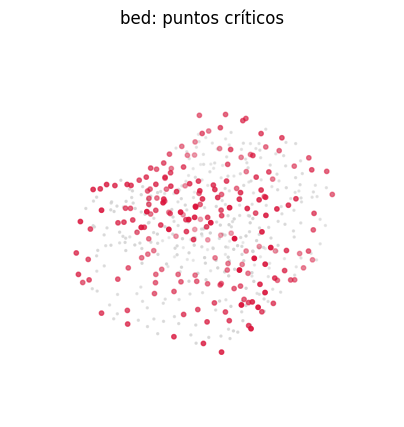

In [ ]:
P = Xte[:1] # toma el primer objeto del test, con forma (1, 512, 3)
with torch.no_grad():
    # aplica h a cada punto, obtiene (1, 512 canales, 512 puntos)
    # busca qué punto tiene el máximo en cada canal y se queda con los índices
    # sin repetir, esos son los puntos críticos
    criticos = h(P.transpose(1, 2)).argmax(dim=2).unique()

    # muestra cuántos puntos críticos hay y compara la salida del modelo con la
    # nube completa y con solo esos puntos, la diferencia es 0 porque el max da el mismo resultado
    print(f"{len(criticos)} de {N} puntos | diferencia en la salida: "
          f"{(red_pointnet(P) - red_pointnet(P[:, criticos])).abs().max():.1e}")

p, c = P[0].cpu(), criticos.cpu() #pasamos la nube y los índices a la CPU para poder graficarlos
ax = plt.figure(figsize=(5, 5)).add_subplot(projection="3d"); ax.set_axis_off()
ax.scatter(p[:, 0], p[:, 2], p[:, 1], s=2, c="lightgray"); ax.scatter(p[c, 0], p[c, 2], p[c, 1], s=10, c="crimson")
ax.set_title(f"{CLASES[yte[0]]}: puntos críticos"); plt.show()

## **4.- PointNet++**


Farthest point sampling, esta función nos permite elegir **m** centros repartidos en cada nube

fps recibe las nubes de puntos y cuántos centros queremos, y devuelve los índices de m puntos repartidos por el objeto, eligiendo cada vez el punto más lejano a los ya elegidos

In [ ]:
def fps(P, m):                          # cada nuevo centro es el punto más lejano a los ya elegidos
    elegidos = [torch.zeros(len(P), dtype=torch.long, device=P.device)] # el primer centro de cada nube es el punto 0
    dist = torch.full(P.shape[:2], float("inf"), device=P.device) # distancia de cada punto al centro más cercano ya elegido; arranca en infinito
    for _ in range(m - 1):
        ultimo = P[torch.arange(len(P)), elegidos[-1]][:, None] # las coordenadas del último centro elegido en cada nube
        dist = torch.minimum(dist, ((P - ultimo) ** 2).sum(-1)) # actualiza la distancia de cada punto con su distancia al nuevo centro, si es menor
        elegidos.append(dist.argmax(1)) # el próximo centro es el punto más lejano a todos los anteriores
    return torch.stack(elegidos, 1) # devuelve los índices de los centros, con forma (B, m)

esta función

* reduce la nube a m centros y le da a cada uno un vector de features que resume la forma de su vecindario local

* toma los centros que eligió fps, arma un grupo de vecinos alrededor de cada uno y resume cada grupo en un vector

In [ ]:
def set_abstraction(P, f, m, r, k, red):
    C = agrupar(P, fps(P, m)[..., None])[:, :, 0]  # obtiene las coordenadas de los m centros elegidos por FPS, con forma (B, m, 3)
    d, idx = torch.cdist(C, P).topk(k, largest=False) # calcula la distancia de cada centro a todos los puntos y se queda con los k más cercanos (ordenados de menor a mayor)
    idx = torch.where(d > r, idx[..., :1], idx) # los vecinos que caen fuera del radio se reemplazan por el más cercano (el propio centro), así resulta un ball query con tamaño fijo k
    g = agrupar(P, idx) - C[:, :, None] # reúne las coordenadas de los vecinos y les resta el centro, de modo que cada grupo queda en coordenadas locales
    if f is not None: g = torch.cat([g, agrupar(f, idx)], -1) # si hay features del nivel anterior, los pega a las coordenadas relativas
    return C, red(g.permute(0, 3, 1, 2)).amax(-1).transpose(1, 2) # reordena a (B, canales, m, k), aplica la mini PointNet, hace un max dentro de cada grupo y devuelve los centros junto con un vector de features por centro

se definen las capas del modelo

In [ ]:
pn2 = nn.ModuleDict({"sa1": mlp([3, 64, 128], nn.Conv2d),
                     "sa2": mlp([131, 128, 256], nn.Conv2d),
                     "sa3": mlp([259, 256, 512]),
                     "cabeza": cabeza(512)}).cuda()

esta función realiza el feedforward de PointNet++

In [ ]:
def red_pn2(P):
    # nivel 1: elige 128 puntos repartidos y para cada uno, mira su vecindario pequeño (aprende detalles finoscomo “aquí hay un borde”)
    C1, f1 = set_abstraction(P, None, 128, 0.25, 32, pn2["sa1"]) # nivel 1: 128 centros, radio 0.25 y 32 vecinos, usa solo coordenadas
    # nivel 2: elige 32 de esos puntos y mira vecindarios más grandes, usando lo que aprendió antes (aprende partes, como “aquí hay una pata”)
    C2, f2 = set_abstraction(C1, f1, 32, 0.5, 32, pn2["sa2"]) # nivel 2: 32 centros elegidos entre los 128 anteriores, radio 0.5 y 32 vecinos, usa los features f1
    # junta esos 32 resúmenes en uno solo y decide qué objeto es, por ejemplo “es una silla”
    return pn2["cabeza"](pn2["sa3"](torch.cat([C2, f2], -1).transpose(1, 2)).amax(-1)) # pega las coordenadas y los features de los 32 centros, aplica sa3 a cada uno, hace un max global y clasifica

tiempos["PointNet++"] = entrenar(red_pn2, pn2, epocas=15)

época  1 | exactitud test 0.489 | 7 s
época  2 | exactitud test 0.804 | 14 s
época  3 | exactitud test 0.852 | 20 s
época  4 | exactitud test 0.905 | 27 s
época  5 | exactitud test 0.894 | 34 s
época  6 | exactitud test 0.884 | 41 s
época  7 | exactitud test 0.910 | 48 s
época  8 | exactitud test 0.924 | 54 s
época  9 | exactitud test 0.927 | 61 s
época 10 | exactitud test 0.931 | 68 s
época 11 | exactitud test 0.930 | 75 s
época 12 | exactitud test 0.934 | 81 s
época 13 | exactitud test 0.936 | 88 s
época 14 | exactitud test 0.941 | 95 s
época 15 | exactitud test 0.942 | 102 s


## **5.- DGCNN**

esta función actualiza cada punto combinándolo con sus k vecinos más cercanos en el espacio de features actual

para cada punto busca sus 10 vecinos más cercanos, mira hacia dónde está cada uno y resume eso en features nuevos. Así cada punto “aprende” cómo es su entorno

In [ ]:
def edge_conv(x, red, k=10):
    idx = torch.cdist(x, x).topk(k + 1, largest=False).indices[..., 1:]     # kNN con los features actuales
    xj = agrupar(x, idx); xi = x[:, :, None].expand_as(xj)
    return red(torch.cat([xi, xj - xi], -1).permute(0, 3, 1, 2)).amax(-1).transpose(1, 2)

guarda las mini redes de cada capa (e1, e2, e3), la que junta todo (global) y el clasificador (cabeza)

In [ ]:
dg = nn.ModuleDict({"e1": mlp([6, 64], nn.Conv2d),
                    "e2": mlp([128, 64], nn.Conv2d),
                    "e3": mlp([128, 128], nn.Conv2d),
                    "global": mlp([256, 512]),
                    "cabeza": cabeza(512)}).cuda()

* aplica edge_conv tres veces seguidas

* en cada vez los vecinos se vuelven a buscar, ahora por parecido y no solo por posición
* al final junta lo aprendido en las tres capas, hace un max sobre todos los puntos y clasifica

In [ ]:
def red_dgcnn(P):
    f1 = edge_conv(P, dg["e1"]) # recibe P, las coordenadas. edge_conv busca los 10 vecinos más cercanos en el espacio. Cada punto sale con 64 features en f1
    f2 = edge_conv(f1, dg["e2"]) # recibe f1. Ahora cdist mide distancias entre esos 64 features, así que los vecinos son los puntos más parecidos, no los más cercanos, sale f2
    f3 = edge_conv(f2, dg["e3"]) #igual, pero con f2. Sale f3, con 128 features por punto
    return dg["cabeza"](dg["global"](torch.cat([f1, f2, f3], -1).transpose(1, 2)).amax(-1))

tiempos["DGCNN"] = entrenar(red_dgcnn, dg, epocas=15)

época  1 | exactitud test 0.669 | 9 s
época  2 | exactitud test 0.780 | 18 s
época  3 | exactitud test 0.857 | 27 s
época  4 | exactitud test 0.845 | 36 s
época  5 | exactitud test 0.904 | 45 s
época  6 | exactitud test 0.907 | 53 s
época  7 | exactitud test 0.867 | 62 s
época  8 | exactitud test 0.906 | 71 s
época  9 | exactitud test 0.903 | 80 s
época 10 | exactitud test 0.926 | 89 s
época 11 | exactitud test 0.934 | 98 s
época 12 | exactitud test 0.928 | 107 s
época 13 | exactitud test 0.930 | 116 s
época 14 | exactitud test 0.931 | 125 s
época 15 | exactitud test 0.931 | 133 s


**Comparación y robustez**

Probamos los tres modelos con nubes modificadas como en un escaneo real: puntos que faltan, una sola cara visible y ruido del sensor.

esta función simula un escaneo desde un solo lado del objeto

In [ ]:
def vista_parcial(X):
    # elige una dirección al azar para cada objeto, proyecta cada punto sobre ella,
    # ordena los puntos por esa proyección y se queda con los índices de la mitad
    # que más avanza en esa dirección
    lado = (X * F.normalize(torch.randn(len(X), 1, 3, device="cuda"), dim=-1)).sum(-1).argsort(1)[:, N // 2:]
    # duplicamos esa mitad para volver a tener 512 puntos y extrae sus coordenadas
    return agrupar(X, lado.repeat(1, 2)[..., None])[:, :, 0]

cinco versiones del test:
* original
* la mitad de los puntos
* el 10 % de los puntos
* vista parcial
ruido gaussiano de 0.04

como el orden de los puntos ya viene al azar, quedarse con los primeros equivale a borrar puntos al azar

In [ ]:
pruebas = {"original": Xte,
           "50 % borrado": Xte[:, :N // 2],
           "90 % borrado": Xte[:, :N // 10],
           "vista parcial": vista_parcial(Xte),
           "ruido σ = 0.04": Xte + 0.04 * torch.randn_like(Xte)}

asocia cada nombre con su función de predicción y sus pesos

In [ ]:
modelos = {"PointNet": (red_pointnet, pointnet),
           "PointNet++": (red_pn2, pn2),
           "DGCNN": (red_dgcnn, dg)}

imprimimos tabla

In [ ]:
print(f"{'':<15}" + "".join(f"{m:>12}" for m in modelos))
print(f"{'tiempo':<15}" + "".join(f"{tiempos[m] / 60:>9.1f} min" for m in modelos))
for nombre, X in pruebas.items():
    print(f"{nombre:<15}" + "".join(f"{exactitud(r, m, X):>12.3f}" for r, m in modelos.values()))

                   PointNet  PointNet++       DGCNN
tiempo               0.4 min      1.7 min      2.2 min
original              0.920       0.942       0.931
50 % borrado          0.925       0.912       0.870
90 % borrado          0.750       0.211       0.389
vista parcial         0.500       0.722       0.562
ruido σ = 0.04        0.902       0.855       0.910


| Modelo | Cómo ve a los vecinos |
| --- | --- |
| PointNet | no los ve, solo el max global |
| PointNet++ | esferas de radio fijo, jerárquico |
| DGCNN | kNN recalculado en cada capa |

El max global hace a PointNet robusto a puntos faltantes. Los modelos que miran vecinos suelen ganar en el test original, pero dependen de que la densidad se parezca a la del entrenamiento.


**Predicciones de cada modelo en ejemplos del test**

ponemos los tres modelos en modo evaluación

In [ ]:
for _, m in modelos.values():
  m.eval()

guardamos las predicciones de cada modelo sobre todo el test, calculadas en lotes de 64 y pasadas a la CPU

In [ ]:
with torch.no_grad():
    preds = {n: torch.cat([r(x).argmax(1) for x in Xte.split(64)]).cpu() for n, (r, m) in modelos.items()}

In [ ]:
ejemplos = torch.randperm(len(Xte))[:8] # elegimos 8 índices del test al azar

muestra 8 nubes de puntos del test elegidas al azar, en una grilla de 2×4, cada nube está coloreada según la altura de sus puntos y tiene como título su clase real y la predicción de cada modelo

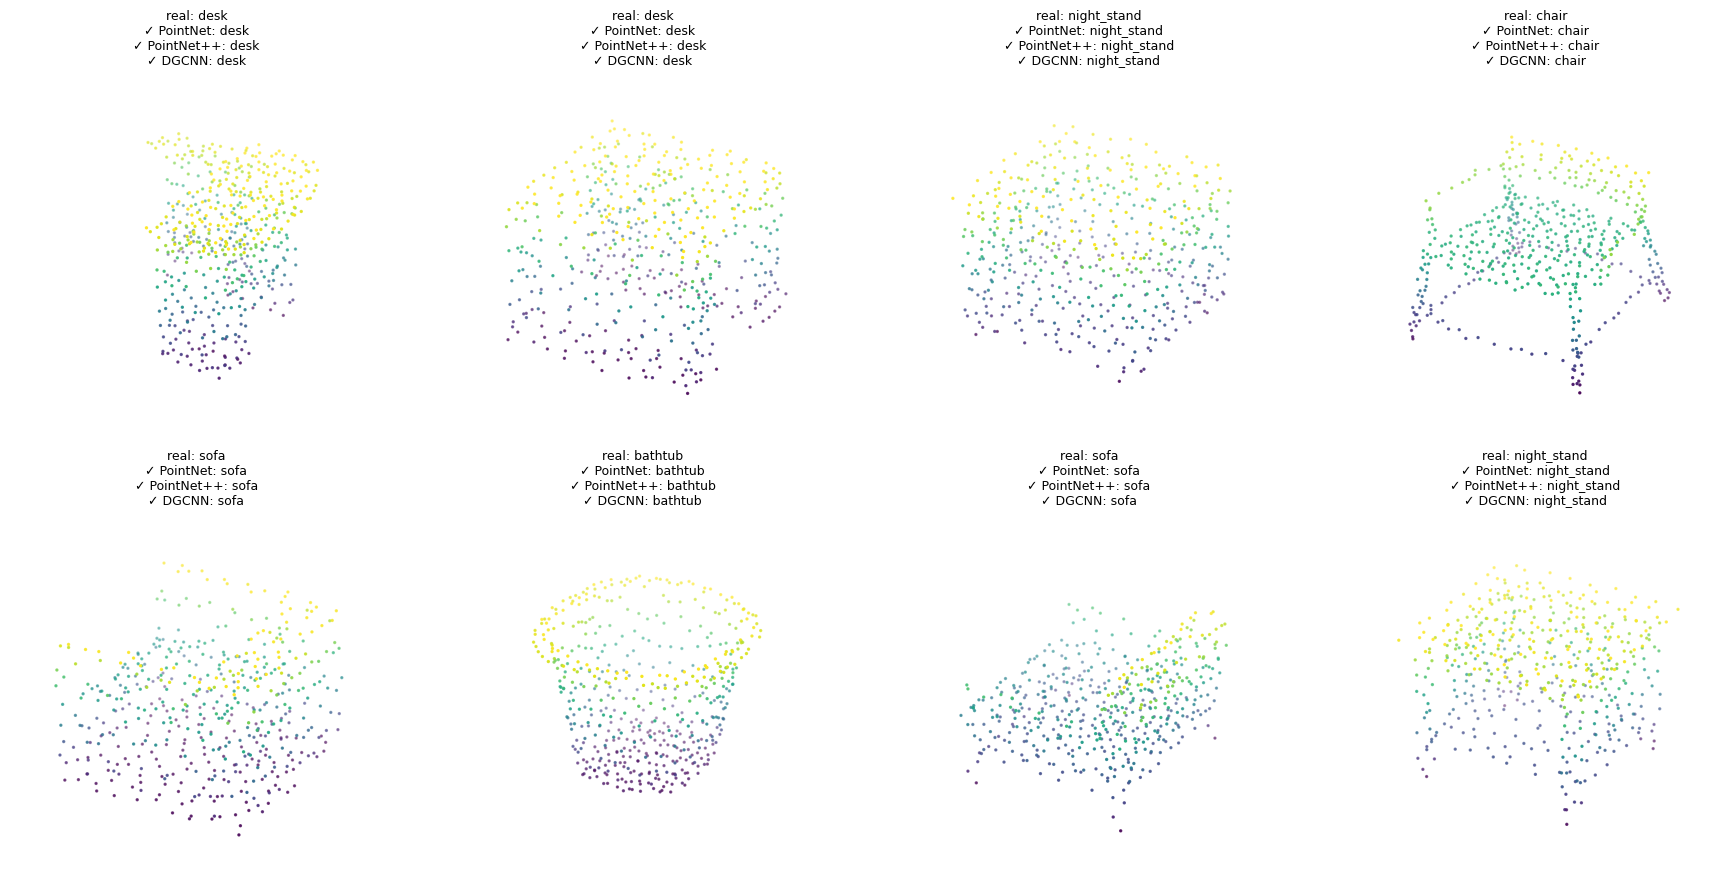

In [ ]:
fig = plt.figure(figsize=(18, 9))
for k, i in enumerate(ejemplos.tolist()):
    p = Xte[i].cpu()
    ax = fig.add_subplot(2, 4, k + 1, projection="3d"); ax.set_axis_off()
    ax.scatter(p[:, 0], p[:, 2], p[:, 1], s=2, c=p[:, 1], cmap="viridis")
    lineas = [f"real: {CLASES[yte[i]]}"] + [f"{'✓' if preds[n][i] == yte[i].item() else '✗'} {n}: {CLASES[preds[n][i]]}" for n in preds]
    ax.set_title("\n".join(lineas), fontsize=9)
plt.tight_layout(); plt.show()

Matriz de confusión de cada modelo. Sirve para ver qué clases se confunden entre sí; por ejemplo, mesa con escritorio o cómoda con mesa de noche.

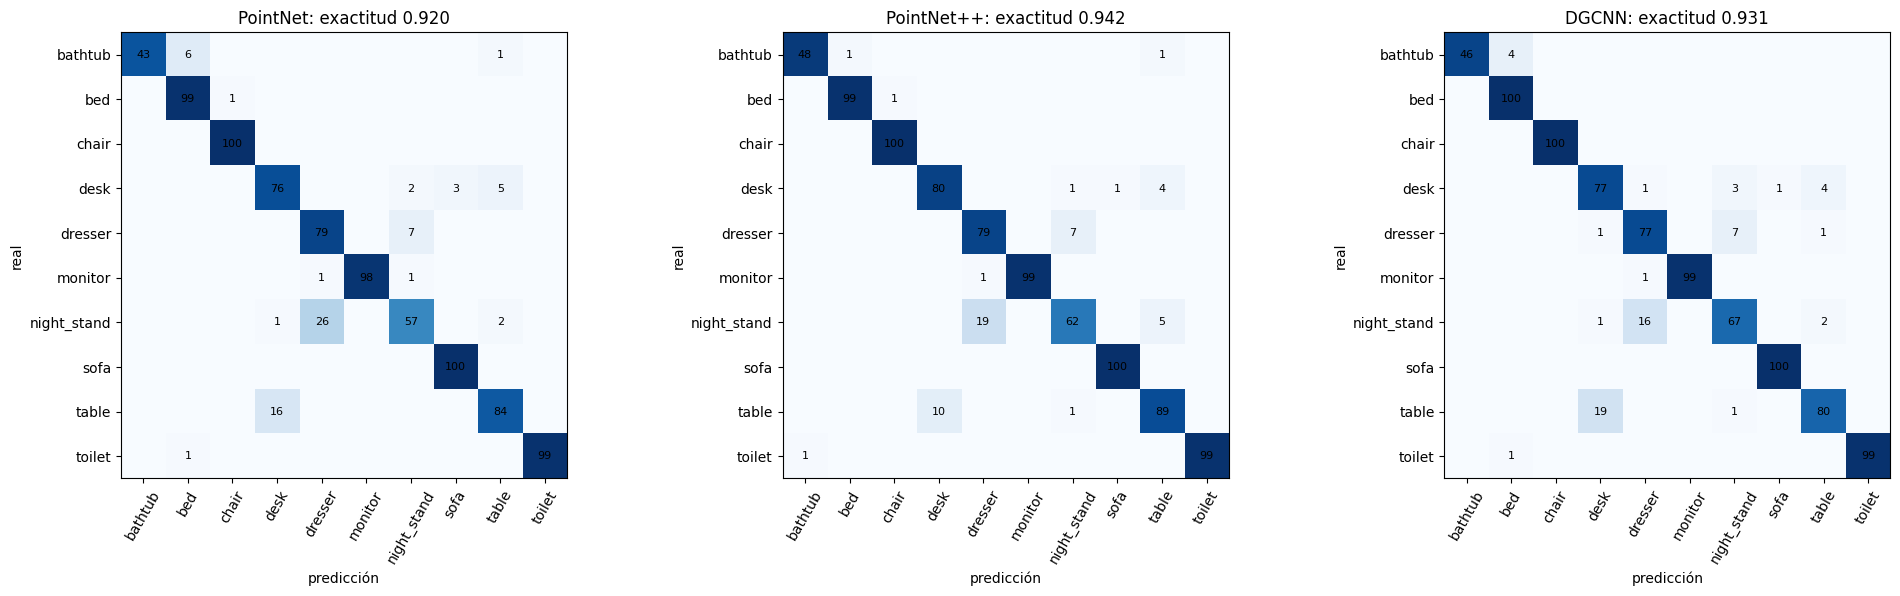

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(20, 6))
for a, (n, pred) in zip(ax, preds.items()):
    M = torch.zeros(10, 10, dtype=torch.long)
    M.index_put_((yte.cpu(), pred), torch.ones_like(pred), accumulate=True)
    a.imshow(M / M.sum(1, keepdim=True), cmap="Blues", vmin=0, vmax=1)
    for r in range(10):
        for c in range(10):
            if M[r, c]: a.text(c, r, M[r, c].item(), ha="center", va="center", fontsize=8)
    a.set_xticks(range(10), CLASES, rotation=60); a.set_yticks(range(10), CLASES)
    a.set_title(f"{n}: exactitud {pred.eq(yte.cpu()).float().mean():.3f}"); a.set_xlabel("predicción"); a.set_ylabel("real")
plt.tight_layout(); plt.show()